# ResilientBite | Campus food demand

**Question.** Can we predict how many portions a hall needs for each meal and menu item before service? The goal is to beat the same-day-last-week forecast on average absolute error and see if the forecast can reduce both extra portions and unmet demand.

**Data.** The supplied ResilientBite CSV covers 32,850 records, 365 dates, three dining halls and 30 menu items. It describes a Chennai campus dining scenario and includes portions prepared, served and requested. This lets us study demand and compare preparation choices on the same rows. The project files give no collection or generation details.

## 1. Load and check the data

One row is one date, dining hall, meal and food item. Demand includes portions served and unmet demand. Remove exact duplicates, rows missing required fields, invalid counts and records that fail the portion totals. For example, demand must equal served plus unmet portions. Keep valid high demand because kitchens need to plan for busy days too.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

source = pd.read_csv("resilientbite_master_extended.csv")
target = "actual_demand_portions"
group = ["dining_hall", "meal", "food_item_id"]
key = ["date"] + group
counts = [target, "actual_preparation_quantity", "quantity_served", "unmet_demand", "leftover_portions"]
flags = ["is_weekend", "is_vacation", "is_exam_period"]

def clean_data(data):
    data = data.copy()
    print("Input rows:", len(data), "| Missing cells:", data.isna().sum().sum())
    data["date"] = pd.to_datetime(data["date"], format="%Y-%m-%d", errors="coerce")
    for col in counts + flags:
        data[col] = pd.to_numeric(data[col], errors="coerce")
    for col in ["dining_hall", "meal"]:
        data[col] = data[col].str.strip().replace("", np.nan)

    print("Duplicate rows removed:", data.duplicated().sum())
    data = data.drop_duplicates()
    needed = key + counts + flags
    print("Rows missing required values or with unreadable values:", data[needed].isna().any(axis=1).sum())
    data = data.dropna(subset=needed)
    valid = data[counts].ge(0).all(axis=1) & data[counts].mod(1).eq(0).all(axis=1)
    valid = valid & data[flags].isin([0, 1]).all(axis=1)
    print("Rows with invalid counts or flags:", (~valid).sum())
    data = data[valid]

    demand_ok = data[target] == data["quantity_served"] + data["unmet_demand"]
    prep_ok = data["actual_preparation_quantity"] == data["quantity_served"] + data["leftover_portions"]
    totals_ok = demand_ok & prep_ok
    print("Rows with inconsistent portion totals:", (~totals_ok).sum())
    data = data[totals_ok]
    if data.duplicated(key).any():
        raise ValueError("Conflicting records for the same date, hall, meal and item.")
    print("Usable rows:", len(data))
    return data.sort_values("date")

df = clean_data(source)
print("Dates:", df["date"].min().date(), "to", df["date"].max().date())

Input rows: 32850 | Missing cells: 0
Duplicate rows removed: 0
Rows missing required values or with unreadable values: 0
Rows with invalid counts or flags: 0
Rows with inconsistent portion totals: 0
Usable rows: 32850
Dates: 2024-01-01 to 2024-12-30


### Cleaning practice with intentional errors

Copy ten rows and introduce a blank demand, preparation recorded as text, a negative demand, and an exaggerated demand of 99,999. Add one exact duplicate. The exaggerated value fails the portion totals check. The cleaning function should leave six valid rows. The notebook uses the original dataset for all charts, training and evaluation.

In [2]:
practice = source.head(10).copy()
practice["actual_preparation_quantity"] = practice["actual_preparation_quantity"].astype(str)
practice.loc[1, target] = np.nan
practice.loc[2, "actual_preparation_quantity"] = "unknown"
practice.loc[3, target] = -5
practice.loc[4, target] = 99999
practice = pd.concat([practice, practice.iloc[[0]]], ignore_index=True)

practice_file = "resilientbite_cleaning_practice.csv"
practice.to_csv(practice_file, index=False)
practice_clean = clean_data(pd.read_csv(practice_file))
assert len(practice_clean) == 6

Input rows: 11 | Missing cells: 1
Duplicate rows removed: 1
Rows missing required values or with unreadable values: 2
Rows with invalid counts or flags: 1
Rows with inconsistent portion totals: 1
Usable rows: 6


## 2. Explore the earlier dates

The first 60% of dates are for training, the next 20% for validation, and the last 20% for the final test. All rows from a date stay together. Use the training dates to look for patterns before comparing models.

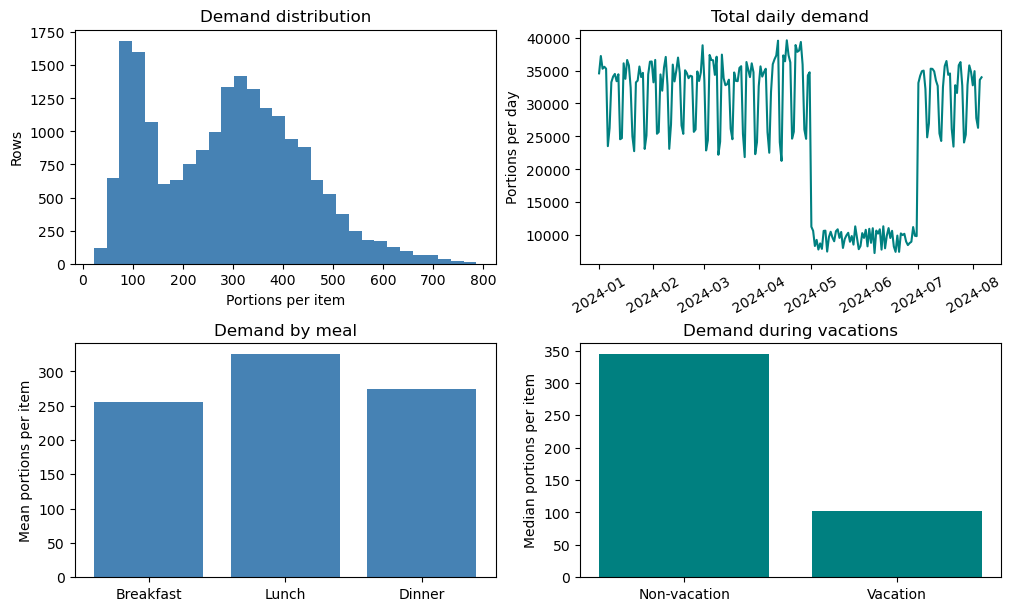

Kept 11 valid training rows above 763 portions.
Training demand range: 22 to 787 portions
Highest average demand: Lunch (325 portions per item)
Median demand was 103 during vacation and 344 otherwise.


In [3]:
dates = df["date"].drop_duplicates().reset_index(drop=True)
validation_start = dates.iloc[int(len(dates) * 0.6)]
test_start = dates.iloc[int(len(dates) * 0.8)]
early = df[df["date"] < validation_start]

daily = early.groupby("date")[target].sum()
by_meal = early.groupby("meal")[target].mean().reindex(["Breakfast", "Lunch", "Dinner"])
vacation = early.groupby("is_vacation")[target].median()

fig, ax = plt.subplots(2, 2, figsize=(10, 6), layout="constrained")
ax[0, 0].hist(early[target], bins=30, color="steelblue")
ax[0, 0].set(title="Demand distribution", xlabel="Portions per item", ylabel="Rows")
ax[0, 1].plot(daily.index, daily, color="teal")
ax[0, 1].set(title="Total daily demand", ylabel="Portions per day")
ax[0, 1].tick_params(axis="x", labelrotation=30)
ax[1, 0].bar(by_meal.index, by_meal, color="steelblue")
ax[1, 0].set(title="Demand by meal", ylabel="Mean portions per item")
ax[1, 1].bar(["Non-vacation", "Vacation"], vacation, color="teal")
ax[1, 1].set(title="Demand during vacations", ylabel="Median portions per item")
plt.show()

q1, q3 = early[target].quantile([0.25, 0.75])
upper_limit = q3 + 1.5 * (q3 - q1)
print(f"Kept {early[target].gt(upper_limit).sum()} valid training rows above {upper_limit:.0f} portions.")
print("Training demand range:", early[target].min(), "to", early[target].max(), "portions")
print("Highest average demand:", by_meal.idxmax(), f"({by_meal.max():.0f} portions per item)")
print(f"Median demand was {vacation[1]:.0f} during vacation and {vacation[0]:.0f} otherwise.")

Lunch has the highest average demand per item. The May and June drop lines up with the vacation period. The vacation comparison shows an association in these records. Other factors that differ by date may also contribute.

## 3. Create simple forecast inputs

Use the calendar flags and demand for the same item, meal and hall yesterday and seven days earlier. Move each past record's date forward and match it to the forecast date. Skip rows where either past value is missing. This drops the first week of this file. Actual attendance, preparation and other same-day outcomes would give the model information it may lack before service.

The test represents a new forecast each day after the previous day's demand is recorded.

In [4]:
data = df.copy()
for days, col in [(1, "yesterday"), (7, "last_week")]:
    history = df[key + [target]].rename(columns={target: col})
    history["date"] = history["date"] + pd.Timedelta(days=days)
    data = data.merge(history, on=key, how="left", validate="one_to_one")

data = data.dropna(subset=["yesterday", "last_week"])
features = flags + ["yesterday", "last_week"]
train = data[data["date"] < validation_start]
val = data[(data["date"] >= validation_start) & (data["date"] < test_start)]
test = data[data["date"] >= test_start]

for name, part in [("Train", train), ("Validation", val), ("Test", test)]:
    print(name, part["date"].min().date(), "to", part["date"].max().date(),
          "|", part["date"].nunique(), "dates |", len(part), "rows")

Train 2024-01-08 to 2024-08-06 | 212 dates | 19080 rows
Validation 2024-08-07 to 2024-10-18 | 73 dates | 6570 rows
Test 2024-10-19 to 2024-12-30 | 73 dates | 6570 rows


## 4. Train models and choose on validation

The baseline uses last week's demand because meal demand can follow a weekly pattern. Linear regression adds up the effects of the inputs. Random Forest averages several decision trees and can learn rules such as a lag being more useful on some days than others. Try three forest depths on validation. Pick the forecast rule with the lowest validation MAE and keep the fitted models for the test.

In [5]:
linear = LinearRegression()
linear.fit(train[features], train[target])

forests = {}
depth_errors = {}
for depth in [4, 8, 12]:
    forest = RandomForestRegressor(n_estimators=60, max_depth=depth, random_state=42)
    forest.fit(train[features], train[target])
    forests[depth] = forest
    depth_errors[depth] = mean_absolute_error(val[target], forest.predict(val[features]).clip(min=0))
best_depth = min(depth_errors, key=depth_errors.get)
forest = forests[best_depth]
print("Validation MAE by forest depth:", pd.Series(depth_errors).round(2).to_dict())

models = {"Linear regression": linear, "Random Forest": forest}
val_predictions = {"Last week": val["last_week"]}
for name, model in models.items():
    val_predictions[name] = model.predict(val[features]).clip(min=0)

validation_mae = pd.Series({
    name: mean_absolute_error(val[target], pred) for name, pred in val_predictions.items()
})
chosen = validation_mae.idxmin()
print("Selected on validation:", chosen)
validation_mae.round(2).to_frame("Validation MAE")

Validation MAE by forest depth: {4: 58.97, 8: 55.99, 12: 56.86}
Selected on validation: Random Forest


,Validation MAE
Last week,65.41
Linear regression,59.18
Random Forest,55.99


## 5. Test performance and errors

MAE is the average size of a miss in portions. RMSE gives large misses more weight. R² compares the model with a constant based on the test mean. Bias is the average forecast minus demand. A positive bias means we forecast too many portions on average.

In [6]:
predictions = pd.DataFrame({"Last week": test["last_week"]})
for name, model in models.items():
    predictions[name] = model.predict(test[features]).clip(min=0)

results = validation_mae.to_frame("Validation MAE")
for name in predictions:
    pred = predictions[name]
    results.loc[name, "Test MAE"] = mean_absolute_error(test[target], pred)
    results.loc[name, "Test RMSE"] = root_mean_squared_error(test[target], pred)
    results.loc[name, "Test R²"] = r2_score(test[target], pred)
    results.loc[name, "Test bias"] = (pred - test[target]).mean()
results.round(2)

,Validation MAE,Test MAE,Test RMSE,Test R²,Test bias
Last week,65.41,81.63,113.19,0.34,23.94
Linear regression,59.18,60.58,76.16,0.70,11.28
Random Forest,55.99,51.91,66.72,0.77,2.87


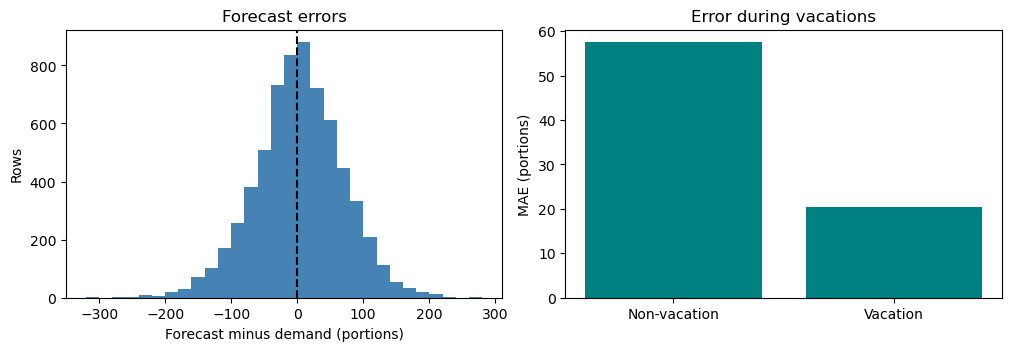

Highest group MAE: Non-vacation (57.5 portions).
Average forecast bias: +2.9 portions.
Largest miss: -320 portions for Chicken Biryani at Dining Hall B on 25 Nov.


,rows,MAE,bias
is_vacation,,,
Non-vacation,5580,57.48,3.85
Vacation,990,20.50,-2.66


In [7]:
errors = test[["date", "dining_hall", "meal", "food_item_name", "is_vacation", target]].copy()
errors["forecast"] = predictions[chosen]
errors["error"] = errors["forecast"] - errors[target]
errors["absolute_error"] = errors["error"].abs()
by_group = errors.groupby("is_vacation").agg(
    rows=("error", "size"), MAE=("absolute_error", "mean"), bias=("error", "mean")
).rename(index={0: "Non-vacation", 1: "Vacation"})

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), layout="constrained")
ax[0].hist(errors["error"], bins=30, color="steelblue")
ax[0].axvline(0, color="black", linestyle="--")
ax[0].set(title="Forecast errors", xlabel="Forecast minus demand (portions)", ylabel="Rows")
ax[1].bar(by_group.index, by_group["MAE"], color="teal")
ax[1].set(title="Error during vacations", ylabel="MAE (portions)")
plt.show()

harder_group = by_group["MAE"].idxmax()
print(f"Highest group MAE: {harder_group} ({by_group.loc[harder_group, 'MAE']:.1f} portions).")
print(f"Average forecast bias: {errors['error'].mean():+.1f} portions.")
worst = errors.loc[errors["absolute_error"].idxmax()]
print(f"Largest miss: {worst['error']:+.0f} portions for {worst['food_item_name']} at "
      f"{worst['dining_hall']} on {worst['date']:%d %b}.")
by_group.round(2)

## 6. Compare preparation rules

On the same test rows, compare recorded preparation with the forecast rounded up and the forecast plus 10%. Excess means prepared portions above demand. Unmet means demand above prepared portions. The comparison assumes demand stays the same under all three rules. Its units are portions per item, meal and hall, while actual food waste is measured separately in kilograms.

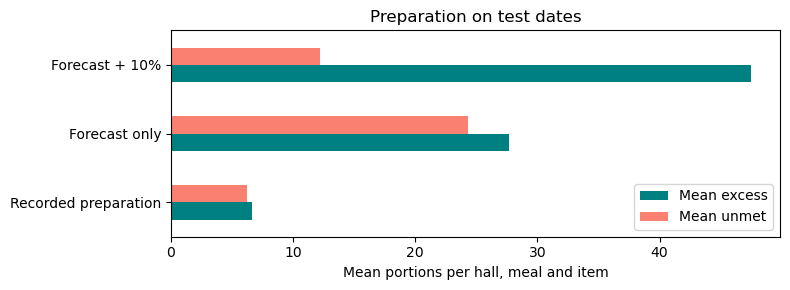

,Mean excess,Mean unmet
Recorded preparation,6.61,6.25
Forecast only,27.64,24.29
Forecast + 10%,47.48,12.20


In [8]:
forecast = predictions[chosen]
prep = pd.DataFrame({
    "Recorded preparation": test["actual_preparation_quantity"],
    "Forecast only": np.ceil(forecast),
    "Forecast + 10%": np.ceil(1.1 * forecast),
})
gap = prep.sub(test[target], axis=0)
policies = pd.DataFrame({
    "Mean excess": gap.clip(lower=0).mean(),
    "Mean unmet": (-gap).clip(lower=0).mean(),
})
assert gap["Recorded preparation"].clip(lower=0).eq(test["leftover_portions"]).all()
assert (-gap["Recorded preparation"]).clip(lower=0).eq(test["unmet_demand"]).all()

policies.plot.barh(figsize=(8, 3), color=["teal", "salmon"], title="Preparation on test dates")
plt.xlabel("Mean portions per hall, meal and item")
plt.tight_layout()
plt.show()
policies.round(2)

## 7. Conclusion

In [9]:
baseline_mae = results.loc["Last week", "Test MAE"]
model_mae = results.loc[chosen, "Test MAE"]
improvement = 100 * (baseline_mae - model_mae) / baseline_mae
print(f"{chosen}: test MAE {model_mae:.2f} portions versus {baseline_mae:.2f} for last week.")
print(f"Relative MAE reduction: {improvement:.1f}%.")

recorded = policies.loc["Recorded preparation"]
better = policies.lt(recorded).all(axis=1)
if better.any():
    print("Rules that improved both measures:", ", ".join(policies.index[better]))
else:
    print("No forecast rule reduced both excess and unmet portions.")
print("The 10% buffer lowers unmet demand compared with forecast only, but adds excess.")

Random Forest: test MAE 51.91 portions versus 81.63 for last week.
Relative MAE reduction: 36.4%.
No forecast rule reduced both excess and unmet portions.
The 10% buffer lowers unmet demand compared with forecast only, but adds excess.


**Limits and next steps.** The file covers one year, the same three halls and a fixed menu. Vacation results come from a short test period, and the file has no student-group data for assessing who experiences shortages. Daily forecasts rely on yesterday's demand being recorded on time. Check the dataset's source and timestamps, try the model on a later term, and measure shortages and waste separately in a kitchen trial.

In [10]:
results.to_csv("model_comparison.csv", index_label="Model")
by_group.to_csv("test_error_by_group.csv", index_label="Calendar")
policies.to_csv("preparation_policy_comparison.csv", index_label="Policy")
errors.join(predictions).join(prep).to_csv("test_predictions.csv", index=False)
pd.Series(depth_errors, name="Validation MAE").to_csv("validation_tuning.csv", index_label="Max depth")